# Phase 2 – Baseline implementation (Option A)
Machine Learning and Related Applications · H.M.A.D. Herath (KIC-BSCCSAI-251P-048)

Paper: Abdu et al. (2024), *Semantic and traditional feature fusion for software defect prediction using hybrid deep learning model*, Scientific Reports 14:14771.

This notebook is a short guided tour. The code lives in the `sdp/` package; the full 30-repeat run is done by `python run_baseline.py` and its tables are in `results/`. Run this notebook from the `notebooks/` folder.

In [1]:
import sys; sys.path.insert(0, "..")          # so that `import sdp` finds the package
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sdp import experiments as ex
from sdp.data import list_releases, load_release
from sdp.config import PAIRS, PAPER
pd.set_option("display.width", 160)

## 1. The data
Twelve PROMISE tables, 20 metrics each. The label is `bug > 0`.

In [2]:
rows = []
for n in list_releases():
    r = load_release(n)
    rows.append(dict(release=n, classes=len(r.y), buggy=int(r.y.sum()), buggy_share=round(r.y.mean(), 3)))
pd.DataFrame(rows)

,release,classes,buggy,buggy_share
0,ant-1.7,745,166,0.223
1,jedit-4.0,306,75,0.245
2,jedit-4.1,312,79,0.253
3,log4j-1.1,109,37,0.339
4,lucene-2.0,195,91,0.467
5,lucene-2.2,247,144,0.583
6,poi-1.5,237,141,0.595
7,poi-3.0,442,281,0.636
8,synapse-1.1,222,60,0.270
9,synapse-1.2,256,86,0.336


## 2. One experiment by hand (Xalan 2.4 → 2.6, 3 repeats)
Shows the steps of `sdp.experiments.fit_and_score`: load, tune on the older release, balance, fit, predict, score.

In [3]:
from sdp.tuning import tune
train, test = load_release("xalan-2.4"), load_release("xalan-2.6")
best_rf, cv_auc, _ = tune("RF", train.X, train.y)           # uses the training release only
print("best RF parameters:", best_rf, " cross-validated AUC on the training release:", round(cv_auc, 3))
res = pd.DataFrame([ex.fit_and_score(train, test, "RF", best_rf, us=True, seed=2026 + r) for r in range(3)])
res.round(3)

best RF parameters: {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 1}  cross-validated AUC on the training release: 0.828


,f1,auc,pofb20,pofb20_per_loc
0,0.499,0.671,0.21,0.403
1,0.496,0.689,0.21,0.448
2,0.573,0.680,0.20,0.424


## 3. Results of the full run
Read from `results/` (written by `python run_baseline.py`). Mean over the five test versions; the paper row is CNN-MLP as printed in the paper.

In [4]:
res_dir = Path("../results")
summ = pd.read_csv(res_dir / "summary_vs_paper.csv")
summ.round(3)

,setting,model,F1,AUC,PofB20,PofB20_per_LOC
0,default,All-buggy rule,0.611,0.500,NaN,NaN
1,default,LR,0.519,0.689,0.226,0.341
2,default,LR + undersampling,0.591,0.688,0.217,0.350
3,default,LR + class weights,0.576,0.687,0.227,0.350
4,default,RF,0.522,0.730,0.250,0.364
5,default,RF + undersampling,0.596,0.713,0.246,0.360
6,default,RF + class weights,0.509,0.723,0.254,0.367
7,tuned,All-buggy rule,0.611,0.500,NaN,NaN
8,tuned,LR,0.499,0.710,0.216,0.352
9,tuned,LR + undersampling,0.605,0.710,0.202,0.352


In [5]:
tun = pd.read_csv(res_dir / "tuning_candidates.csv")
tun[tun["rank"] == 1][["train_release", "model", "params", "mean_auc"]].round(3)

,train_release,model,params,mean_auc
2,xalan-2.4,LR,{'logisticregression__C': 1.0},0.800
20,xalan-2.4,RF,"{'max_depth': 10, 'max_features': 0.5, 'min_sa...",0.828
24,poi-1.5,LR,{'logisticregression__C': 0.1},0.791
35,poi-1.5,RF,"{'max_depth': 5, 'max_features': 'sqrt', 'min_...",0.819
47,jedit-4.0,LR,{'logisticregression__C': 0.1},0.796
65,jedit-4.0,RF,"{'max_depth': 10, 'max_features': 'sqrt', 'min...",0.812
69,lucene-2.0,LR,{'logisticregression__C': 0.01},0.758
81,lucene-2.0,RF,"{'max_depth': 5, 'max_features': 'sqrt', 'min_...",0.766
93,synapse-1.1,LR,{'logisticregression__C': 0.1},0.782
104,synapse-1.1,RF,"{'max_depth': 5, 'max_features': 'sqrt', 'min_...",0.782


In [6]:
cvd = pd.read_csv(res_dir / "results_cross_version_default.csv")
cvt = pd.read_csv(res_dir / "results_cross_version_tuned.csv")
view = pd.concat([cvd.assign(setting="default"), cvt.assign(setting="tuned")])
view = view[view.model.isin(["All-buggy rule", "LR", "RF", "RF + undersampling"])]
view.pivot_table(index="test", columns=["model", "setting"], values="auc").round(3)

model       All-buggy rule            LR             RF        RF + undersampling       
setting            default tuned default  tuned default  tuned            default  tuned
test                                                                                    
jedit-4.1              0.5   0.5   0.812  0.821   0.843  0.844              0.827  0.839
lucene-2.2             0.5   0.5   0.646  0.669   0.653  0.655              0.651  0.655
poi-3.0                0.5   0.5   0.653  0.708   0.710  0.749              0.714  0.753
synapse-1.2            0.5   0.5   0.672  0.689   0.725  0.735              0.694  0.706
xalan-2.6              0.5   0.5   0.662  0.662   0.720  0.732              0.678  0.682

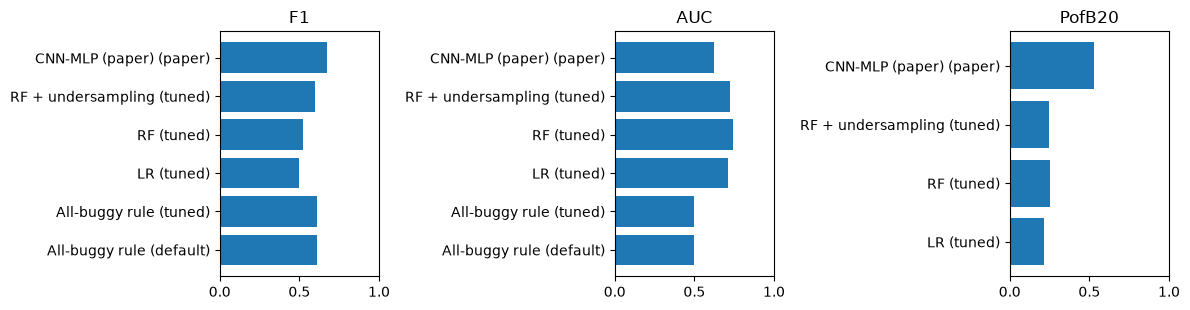

In [7]:
s = summ[summ.model.isin(["All-buggy rule", "LR", "RF", "RF + undersampling", "CNN-MLP (paper)"])]
s = s[(s.setting == "tuned") | (s.setting == "paper") | (s.model == "All-buggy rule") & (s.setting == "default")]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, m in zip(ax, ["F1", "AUC", "PofB20"]):
    a.barh(s.model + " (" + s.setting + ")", s[m]); a.set_title(m); a.set_xlim(0, 1)
plt.tight_layout(); plt.show()